   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa
(150, 6)
Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species           object
dtype: object
               Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
count  150.000000     150.000000    150.000000     150.000000    150.000000
mean    75.500000       5.843333      3.054000       3.758667      1.198667
std     43.445368       0.828066      0.433594       1.764420      0.763161
min      1.000000       4.300000      2.000000       1.000000

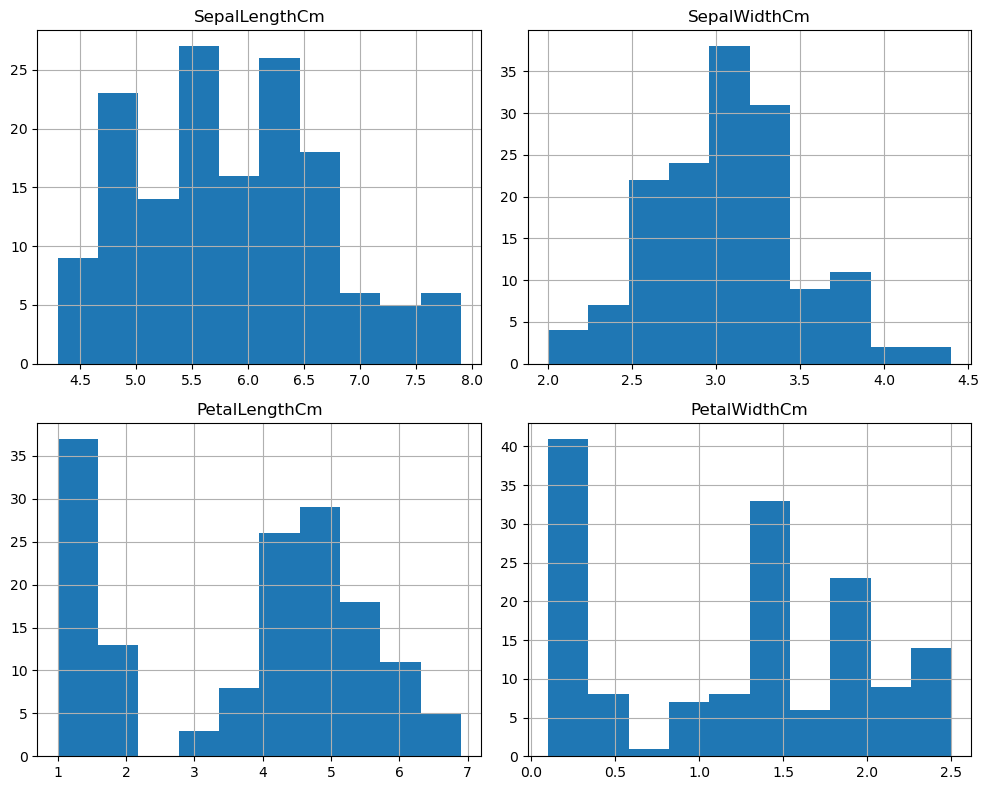

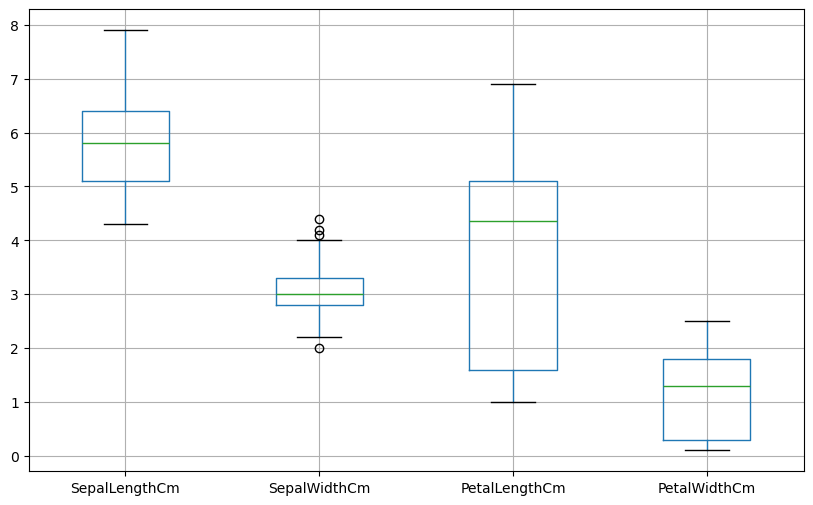

Features: (150, 4)
Target: (150,)
Model_Accuracy: 0.9333333333333333
Confusion Matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
import pandas as pd 
import matplotlib.pyplot as plt
path='iris.csv'
df=pd.read_csv(path)
print(df.head())
print(df.shape)
print(df.dtypes)
print(df.describe())
df_copy=df.copy()
df_copy=df.drop(columns='Id')
num_cols=df_copy.select_dtypes(include='number').columns
for col in num_cols:
    q1=df_copy[col].quantile(0.25)
    q3=df_copy[col].quantile(0.75)
    iqr=q3-q1
    lower=q1-1.5*iqr
    upper=q3+1.5*iqr
    outlier = df_copy[(df_copy[col] < lower) | (df_copy[col] > upper)]    
    print(f"\nColumn: {col}")
    print("Lower Bound:", lower)
    print("Upper Bound:", upper)
    print("Number of Outliers:", len(outlier))
    print(outlier[[col]])

print(df_copy['Species'].value_counts())

df_copy.hist(figsize=(10,8))
plt.tight_layout()
plt.show()

df_copy.boxplot(figsize=(10, 6))
plt.show()
X = df_copy[['SepalLengthCm', 'SepalWidthCm',
             'PetalLengthCm', 'PetalWidthCm']]

y = df_copy['Species']

print("Features:", X.shape)
print("Target:", y.shape)

x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
model=DecisionTreeClassifier(random_state=42)
model.fit(x_train,y_train)
y_pred=model.predict(x_test)
accuracy=accuracy_score(y_test,y_pred)
print(f"Model_Accuracy: {accuracy}")
cm=confusion_matrix(y_test,y_pred)

print(f"Confusion Matrix:\n {cm}")